# 06 Final comparison: is a neural network worth it on a kiosk?

**The director's question.** The kiosks have modest CPUs, the team is small and the budget is limited.
Is a neural network worth it in production, or would a simpler classical model do the job?

**Goal of this notebook.** We answer with measures, in four steps:

1. **Classical models**, with no neural network at all: logistic regression and random forest on the
   pixels or on hand-made colour and texture features. Their settings are chosen on the validation set.
2. **Our neural models**, trained again with the exact recipes of notebooks 03 and 05.
3. **The final test**: every model is scored **once** on the 220 test paintings, never used before.
4. **Speed and size on a CPU**: the time to classify one photo with 1, 2 and 4 CPU threads (a kiosk has
   few cores), the size of the model file and the training time.

Then we write our recommendation.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image

from museum_guide.baselines import hand_features, hand_features_batch, make_forest, make_logreg, tune_on_validation
from museum_guide.benchmark import cpu_threads, latency_ms, size_mb
from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import channel_stats, class_names, load_images, load_split_images, standardise
from museum_guide.evaluation import (bootstrap_ci, confusion_matrix, load_results, macro_f1, paired_bootstrap,
                                     per_class_report, save_results)
from museum_guide.features import cached_features
from museum_guide.models import ResNetClassifier, count_parameters, count_trainable
from museum_guide.plots import CLASS_COLORS, PALETTE, plot_confusion, save_figure
from museum_guide.recipes import FINETUNE, MLP_REGULARISED, train_finetune, train_head, train_mlp
from museum_guide.training import make_loaders, predict

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
loss_fn = nn.CrossEntropyLoss()

# The test set is unlocked here, and only here.
images224, meta = load_split_images(224, include_test=True)
images32, _ = load_split_images(32, include_test=True)
classes = class_names(meta)
masks = {s: (meta["split"] == s).to_numpy() for s in ("train", "val", "test")}
y = {s: images224[s][1] for s in masks}
print({s: int(m.sum()) for s, m in masks.items()}, "| seeds", SEEDS, "| CPU threads", torch.get_num_threads())

{'train': 1061, 'val': 219, 'test': 220} | seeds [0, 1, 2] | CPU threads 8


## 1. Classical models

**What we do.** We prepare three inputs:

- **pixels**: the 32 x 32 x 3 = 3 072 pixel values, like the MLP;
- **hand-made features**: 102 numbers per painting that a person designed (code in
  `src/museum_guide/baselines.py`): a colour histogram in HSV space (hue x saturation x brightness,
  72 numbers), simple colour statistics (10), and a histogram of the directions of the edges with the
  edge strength, at two scales (20), to describe the texture and the brush strokes;
- **ResNet features**: the 512 numbers of notebook 05. A classical classifier on these features is a
  "hybrid": the neural network only describes the image.

On each input we train a **logistic regression** (a linear model) and, on the hand-made features, a
**random forest** (500 decision trees that vote). For each model we try a few settings and keep the
best one on the **validation** set.

In [2]:
t0 = time.perf_counter()
X_hand = hand_features_batch(load_images(meta, 64))
hand_seconds = time.perf_counter() - t0
pix = {s: images32[s][0].flatten(1).numpy().astype(np.float32) / 255 for s in masks}
hand = {s: X_hand[m] for s, m in masks.items()}
features, feature_seconds_per_image = cached_features(meta)
feat = {s: features[torch.tensor(m)] for s, m in masks.items()}
print(f"hand-made features: {X_hand.shape} in {hand_seconds:.1f} s | ResNet features: {tuple(features.shape)}")

classical_setups = {
    "logistic regression on pixels": (make_logreg, [{"C": c} for c in (1e-4, 1e-3, 1e-2, 1e-1)], pix),
    "logistic regression on hand-made features": (make_logreg, [{"C": c} for c in (1e-3, 1e-2, 1e-1, 1.0, 10.0)], hand),
    "random forest on hand-made features": (make_forest, [{"min_samples_leaf": m, "max_features": f}
                                                          for m in (1, 3) for f in ("sqrt", 0.3)], hand),
    "logistic regression on ResNet features": (make_logreg, [{"C": c} for c in (1e-3, 1e-2, 1e-1, 1.0)],
                                               {s: v.numpy() for s, v in feat.items()}),
}
classical, tuning = {}, {}
for name, (build, grid, X) in classical_setups.items():
    t0 = time.perf_counter()
    model, best, scores = tune_on_validation(build, grid, X["train"], y["train"].numpy(), X["val"], y["val"].numpy())
    classical[name] = {"model": model, "setting": best, "X": X, "fit_seconds": (time.perf_counter() - t0) / len(grid)}
    tuning[name] = scores
pd.DataFrame([{"model": n, "setting": ", ".join(f"{k}={v}" for k, v in c["setting"].items()),
               "val_acc": max(tuning[n].values())} for n, c in classical.items()]).set_index("model").round(3)

hand-made features: (1500, 102) in 3.0 s | ResNet features: (1500, 512)


,setting,val_acc
model,,
logistic regression on pixels,C=0.0001,0.406
logistic regression on hand-made features,C=1.0,0.612
random forest on hand-made features,"min_samples_leaf=1, max_features=sqrt",0.635
logistic regression on ResNet features,C=0.01,0.881


**What we see.**

- On the **pixels**, the logistic regression reaches 40.6 % on validation, about the same as our MLP on
  pixels before regularisation (39 %).
- With **hand-made features**, the classical models do much better: 61.2 % for the logistic regression
  and **63.5 % for the random forest**. This beats our best MLP on pixels (45.5 %): with 1 061 images,
  102 well-chosen numbers are more useful than 3 072 raw pixels.
- With the **ResNet features**, a plain logistic regression reaches 88.1 %, exactly like our linear
  probe. Once the features are good, the classifier on top matters little.

## 2. Our neural models, trained again

**What we do.** We train our three neural models again with the recipes of notebooks 03 and 05
(`src/museum_guide/recipes.py`), with the same 3 seeds. Their validation accuracy must be exactly the
one of those notebooks: this checks that our results can be reproduced.

In [3]:
mean32, std32 = channel_stats(images32["train"][0])
mlp_data = {s: standardise(images32[s][0], mean32, std32) for s in masks}
mlp_loaders = make_loaders(mlp_data["train"], y["train"], mlp_data["val"], y["val"], batch_size=64)
img_loaders = make_loaders(*images224["train"], *images224["val"], batch_size=32, eval_batch_size=128)

neural = {"regularised MLP on pixels": [], "ResNet18 frozen + linear head": [], "ResNet18 fine-tuned (layer4)": []}
for seed in SEEDS:
    model, h = train_mlp(mlp_loaders, seed=seed, **{k: v for k, v in MLP_REGULARISED.items() if k != "size"})
    neural["regularised MLP on pixels"].append({"model": model, "seconds": sum(h["epoch_time"])})
    head, h = train_head(feat["train"], y["train"], feat["val"], y["val"], seed=seed)
    deployed = ResNetClassifier(train_from=None, head=head).eval()  # the full kiosk model: ResNet body + our head
    neural["ResNet18 frozen + linear head"].append(
        {"model": deployed, "head": head, "seconds": sum(h["epoch_time"]) + feature_seconds_per_image * masks["train"].sum()})
    cfg = dict(FINETUNE, epochs=2) if FAST_RUN else FINETUNE
    model, h = train_finetune(img_loaders, seed=seed, **cfg)
    neural["ResNet18 fine-tuned (layer4)"].append({"model": model, "seconds": sum(h["epoch_time"])})


def accuracy(model, X, labels):
    logits, _ = predict(model, make_loaders(X, labels, X, labels, eval_batch_size=128).val)
    return (logits.argmax(dim=1) == labels).float().mean().item()


inputs = {"regularised MLP on pixels": mlp_data, "ResNet18 frozen + linear head": {s: images224[s][0] for s in masks},
          "ResNet18 fine-tuned (layer4)": {s: images224[s][0] for s in masks}}
previous = {"regularised MLP on pixels": [r["val_acc"] for r in load_results("03_monitoring")["tool_runs"] if r["tool"] == "all together"],
            "ResNet18 frozen + linear head": [r["val_acc"] for r in load_results("05_resnet")["head_runs"] if r["head"] == "linear probe"],
            "ResNet18 fine-tuned (layer4)": [r["val_acc"] for r in load_results("05_resnet")["finetune_runs"]]}
check = pd.DataFrame([{"model": n, "seed": s, "val_acc_now": accuracy(r["model"], inputs[n]["val"], y["val"]),
                       "val_acc_before": previous[n][k] if not FAST_RUN else float("nan")}
                      for n, runs in neural.items() for k, (s, r) in enumerate(zip(SEEDS, runs))])
check["same"] = (check["val_acc_now"] - check["val_acc_before"]).abs() < 1e-4
check.round(4)

,model,seed,val_acc_now,val_acc_before,same
0,regularised MLP on pixels,0,0.4612,0.4612,True
1,regularised MLP on pixels,1,0.4566,0.4566,True
2,regularised MLP on pixels,2,0.4475,0.4475,True
3,ResNet18 frozen + linear head,0,0.8813,0.8813,True
4,ResNet18 frozen + linear head,1,0.8813,0.8813,True
5,ResNet18 frozen + linear head,2,0.8813,0.8813,True
6,ResNet18 fine-tuned (layer4),0,0.8584,0.8584,True
7,ResNet18 fine-tuned (layer4),1,0.8493,0.8493,True
8,ResNet18 fine-tuned (layer4),2,0.8539,0.8539,True


**What we see.** The 9 runs give exactly the validation accuracy of notebooks 03 and 05 (column
`same`). Our results can be reproduced from the code and the seeds.

## 3. The final test (measured once)

**What we do.** Every model now predicts the 220 test paintings. For each model we report:

- the **test accuracy** (mean over the 3 seeds for the neural models);
- the **macro F1** (the mean of the F1 scores of the 5 styles, so that each style counts the same);
- a **95 % interval** of the accuracy, by bootstrap: we redraw the 220 test paintings with replacement
  5 000 times and look at how much the accuracy moves. With only 220 paintings, it moves a lot.

In [4]:
def test_predictions(name):
    """One array of test predictions per seed (one for the classical models)."""
    if name == "always the most frequent style":
        majority = int(torch.bincount(y["train"]).argmax())
        return [np.full(masks["test"].sum(), majority)]
    if name in classical:
        c = classical[name]
        return [c["model"].predict(c["X"]["test"])]
    return [predict(r["model"], make_loaders(inputs[name]["test"], y["test"], inputs[name]["test"], y["test"],
                                             eval_batch_size=128).val)[0].argmax(dim=1).numpy() for r in neural[name]]


family = {"always the most frequent style": "baseline", **{n: "classical" for n in classical}, **{n: "neural" for n in neural}}
family["logistic regression on ResNet features"] = "hybrid"
order = ["always the most frequent style", "logistic regression on pixels", "logistic regression on hand-made features",
         "random forest on hand-made features", "regularised MLP on pixels", "ResNet18 fine-tuned (layer4)",
         "logistic regression on ResNet features", "ResNet18 frozen + linear head"]
y_test = y["test"].numpy()
preds = {n: test_predictions(n) for n in order}
rows = []
for n in order:
    accs = [float((p == y_test).mean()) for p in preds[n]]
    lo, hi = bootstrap_ci(preds[n][0] == y_test)
    rows.append({"model": n, "family": family[n], "test_acc": np.mean(accs), "test_acc_std": np.std(accs, ddof=1) if len(accs) > 1 else 0.0,
                 "ci_low": lo, "ci_high": hi, "macro_f1": np.mean([macro_f1(torch.tensor(y_test), torch.tensor(p), 5) for p in preds[n]])})
test_table = pd.DataFrame(rows).set_index("model")
test_table.round(3)

,family,test_acc,test_acc_std,ci_low,ci_high,macro_f1
model,,,,,,
always the most frequent style,baseline,0.191,0.000,0.141,0.245,0.064
logistic regression on pixels,classical,0.327,0.000,0.268,0.391,0.312
logistic regression on hand-made features,classical,0.614,0.000,0.550,0.677,0.612
random forest on hand-made features,classical,0.673,0.000,0.609,0.736,0.667
regularised MLP on pixels,neural,0.414,0.005,0.345,0.473,0.401
ResNet18 fine-tuned (layer4),neural,0.879,0.009,0.841,0.927,0.876
logistic regression on ResNet features,hybrid,0.845,0.000,0.795,0.891,0.845
ResNet18 frozen + linear head,neural,0.830,0.010,0.786,0.886,0.829


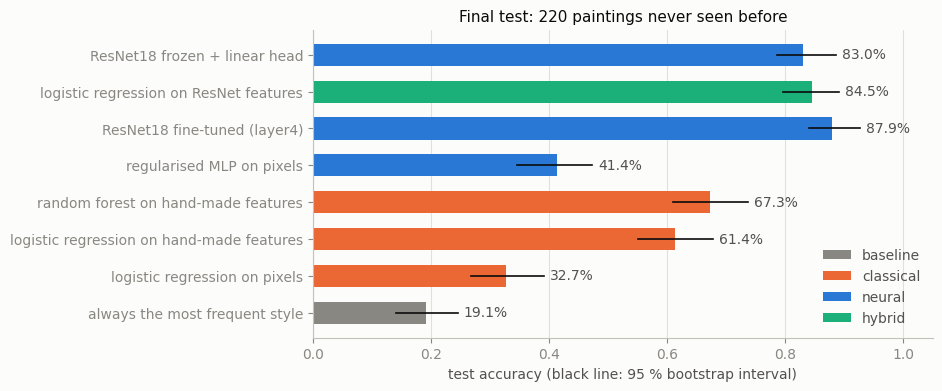

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = {"baseline": "#898781", "classical": PALETTE[1], "hybrid": PALETTE[2], "neural": PALETTE[0]}
yy = np.arange(len(order))
for k, n in enumerate(order):
    r = test_table.loc[n]
    ax.barh(k, r["test_acc"], color=colors[r["family"]], height=0.6,
            label=r["family"] if r["family"] not in ax.get_legend_handles_labels()[1] else None)
    ax.plot([r["ci_low"], r["ci_high"]], [k, k], color="#0b0b0b", linewidth=1.2)
    ax.text(r["ci_high"] + 0.01, k, f"{r['test_acc']:.1%}", va="center", color="#52514e")
ax.set_yticks(yy, order)
ax.set_xlim(0, 1.05)
ax.set_xlabel("test accuracy (black line: 95 % bootstrap interval)")
ax.set_title("Final test: 220 paintings never seen before")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_figure(fig, "06_test_accuracy")
plt.show()

**Are the differences real?** For the key pairs we compute the difference of accuracy **on the same
test paintings**, with its bootstrap interval (seed 0 of each neural model). If the interval does not
contain 0, the difference is not luck.

In [6]:
pairs = [("ResNet18 frozen + linear head", "random forest on hand-made features"),
         ("ResNet18 frozen + linear head", "regularised MLP on pixels"),
         ("random forest on hand-made features", "regularised MLP on pixels"),
         ("ResNet18 frozen + linear head", "ResNet18 fine-tuned (layer4)"),
         ("ResNet18 frozen + linear head", "logistic regression on ResNet features")]
paired = pd.DataFrame([{"A": a, "B": b, **paired_bootstrap(preds[a][0] == y_test, preds[b][0] == y_test)} for a, b in pairs])
paired.round(3)

,A,B,diff,ci_low,ci_high,share_not_better
0,ResNet18 frozen + linear head,random forest on hand-made features,0.164,0.091,0.241,0.000
1,ResNet18 frozen + linear head,regularised MLP on pixels,0.427,0.350,0.505,0.000
2,random forest on hand-made features,regularised MLP on pixels,0.264,0.195,0.332,0.000
3,ResNet18 frozen + linear head,ResNet18 fine-tuned (layer4),-0.050,-0.091,-0.009,0.993
4,ResNet18 frozen + linear head,logistic regression on ResNet features,-0.009,-0.036,0.018,0.814


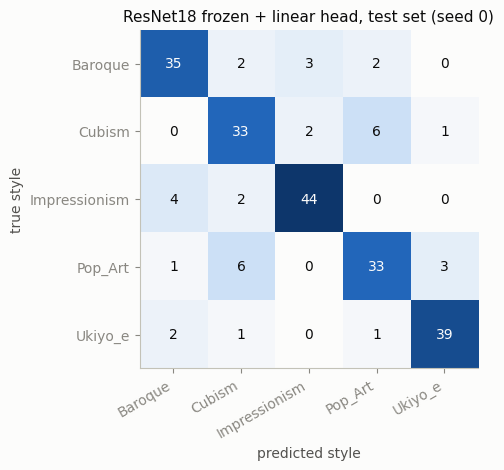

,recall,precision,f1,images
Baroque,0.833,0.833,0.833,42
Cubism,0.786,0.750,0.767,42
Impressionism,0.880,0.898,0.889,50
Pop_Art,0.767,0.786,0.776,43
Ukiyo_e,0.907,0.907,0.907,43


In [7]:
best_name = "ResNet18 frozen + linear head"
cm = confusion_matrix(torch.tensor(y_test), torch.tensor(preds[best_name][0]), 5)
plot_confusion(cm, classes, "ResNet18 frozen + linear head, test set (seed 0)", save_as="06_confusion_test")
per_class = per_class_report(cm, classes)
per_class.round(3)

**What we see.** **The pretrained neural network wins clearly.** On the 220 test paintings:

- the best classical model (random forest on hand-made features) reaches **67.3 %** (interval 60.9 to
  73.6 %);
- the ResNet18 models reach **83.0 %** (frozen + linear head) to **87.9 %** (fine-tuned). The logistic
  regression on ResNet features gives 84.5 %;
- our MLP on pixels reaches 41.4 %, and the logistic regression on pixels 32.7 %.

The paired comparisons show that these gaps are real:

- the frozen ResNet + linear head is **16.4 points** better than the random forest (interval 9.1 to
  24.1 points) and 42.7 points better than the MLP. In none of the 5 000 redraws is it not better;
- the random forest is also clearly better than our MLP (+26.4 points).

**Frozen or fine-tuned?** Here the validation and the test disagree:

- on validation, the frozen model was better (88.1 % against 85.4 %);
- on test, the fine-tuned model is better (87.9 % against 83.0 %; for seed 0 the interval of the
  difference is 0.9 to 9.1 points).

With about 220 paintings in each set, a score moves by about 5 points just by chance (see the
intervals), so our data cannot separate these two variants. We chose the frozen model on validation
**before** looking at the test, and we keep this choice: picking a model on its test score would make
that score too optimistic. The logistic regression on ResNet features (84.5 %) belongs to the same
group.

**Per style** (frozen model, seed 0): Ukiyo-e (91 %) and Impressionism (88 %) are the easiest, Pop Art
(77 %) and Cubism (79 %) the hardest, as on validation.

## 4. Speed and size on a CPU

**What we do.** On a kiosk, a visitor takes **one** photo and waits. So we time the classification of
one photo at a time, from a 224 x 224 colour image to the predicted style: resizing, features and the
model itself. We repeat it 50 times (after 5 warm-up runs) and report the median and the 95th
percentile, with 1, 2 and 4 CPU threads. A kiosk CPU is slower than this laptop: the 1-thread numbers
are the closest to a modest kiosk.

We also report the size of the model file, the number of trained parameters and the training time.

In [8]:
photos = [Image.fromarray(img.permute(1, 2, 0).numpy()) for img in images224["test"][0][:20]]


def to_tensor(photo, size):
    photo = photo if photo.size == (size, size) else photo.resize((size, size), Image.Resampling.BILINEAR)
    return torch.from_numpy(np.asarray(photo).copy()).permute(2, 0, 1).unsqueeze(0)


mlp_model = neural["regularised MLP on pixels"][0]["model"].eval()
resnet_model = neural["ResNet18 frozen + linear head"][0]["model"].eval()
finetuned_model = neural["ResNet18 fine-tuned (layer4)"][0]["model"].eval()
for c in classical.values():
    final = c["model"][-1] if hasattr(c["model"], "steps") else c["model"]
    if hasattr(final, "n_jobs"):
        final.set_params(n_jobs=1)  # one photo at a time: no parallel trees

pipelines = {
    "logistic regression on pixels": lambda p: classical["logistic regression on pixels"]["model"].predict(
        to_tensor(p, 32).flatten(1).numpy().astype(np.float32) / 255),
    "logistic regression on hand-made features": lambda p: classical["logistic regression on hand-made features"]["model"].predict(
        hand_features(to_tensor(p, 64)[0])[None]),
    "random forest on hand-made features": lambda p: classical["random forest on hand-made features"]["model"].predict(
        hand_features(to_tensor(p, 64)[0])[None]),
    "regularised MLP on pixels": lambda p: mlp_model(standardise(to_tensor(p, 32), mean32, std32)).argmax(dim=1),
    "ResNet18 fine-tuned (layer4)": lambda p: finetuned_model(to_tensor(p, 224)).argmax(dim=1),
    "logistic regression on ResNet features": lambda p: classical["logistic regression on ResNet features"]["model"].predict(
        resnet_model.features(to_tensor(p, 224)).numpy()),
    "ResNet18 frozen + linear head": lambda p: resnet_model(to_tensor(p, 224)).argmax(dim=1),
}
speed = []
with torch.no_grad():
    for name, fn in pipelines.items():
        row = {"model": name}
        for n in (1, 2, 4):
            with cpu_threads(n):
                t = latency_ms(fn, photos)
            row[f"ms_{n}_thread"], row[f"p95_ms_{n}_thread"] = t["median_ms"], t["p95_ms"]
        speed.append(row)
speed_table = pd.DataFrame(speed).set_index("model")


def model_size(name):
    if name in classical:
        return size_mb(classical[name]["model"]) + (size_mb(resnet_model.backbone) if "ResNet" in name else 0)
    return size_mb(neural[name][0]["model"])


def trained_parameters(name):
    if name in neural:
        m = neural[name][0]
        return count_parameters(m["head"]) if "head" in m else count_trainable(m["model"])
    return None


speed_table["size_mb"] = [model_size(n) for n in speed_table.index]
speed_table["trained_parameters"] = [trained_parameters(n) for n in speed_table.index]
speed_table["training_seconds"] = [np.mean([r["seconds"] for r in neural[n]]) if n in neural else classical[n]["fit_seconds"]
                                   for n in speed_table.index]
speed_table["test_acc"] = test_table.loc[speed_table.index, "test_acc"]
speed_table[["ms_1_thread", "ms_2_thread", "ms_4_thread", "p95_ms_1_thread", "size_mb", "trained_parameters",
             "training_seconds", "test_acc"]].round(3)

,ms_1_thread,ms_2_thread,ms_4_thread,p95_ms_1_thread,size_mb,trained_parameters,training_seconds,test_acc
model,,,,,,,,
logistic regression on pixels,0.354,0.347,0.356,0.436,0.136,NaN,1.203,0.327
logistic regression on hand-made features,1.491,1.367,1.578,2.221,0.006,NaN,0.031,0.614
random forest on hand-made features,24.446,23.322,23.501,30.452,25.850,NaN,1.014,0.673
regularised MLP on pixels,0.358,0.437,0.392,0.577,6.841,1707525.0,10.349,0.414
ResNet18 fine-tuned (layer4),52.789,36.750,26.642,55.528,44.796,8396293.0,152.717,0.879
logistic regression on ResNet features,52.841,37.007,27.068,55.454,44.806,NaN,0.041,0.845
ResNet18 frozen + linear head,52.685,37.001,26.103,54.893,44.801,2565.0,16.936,0.830


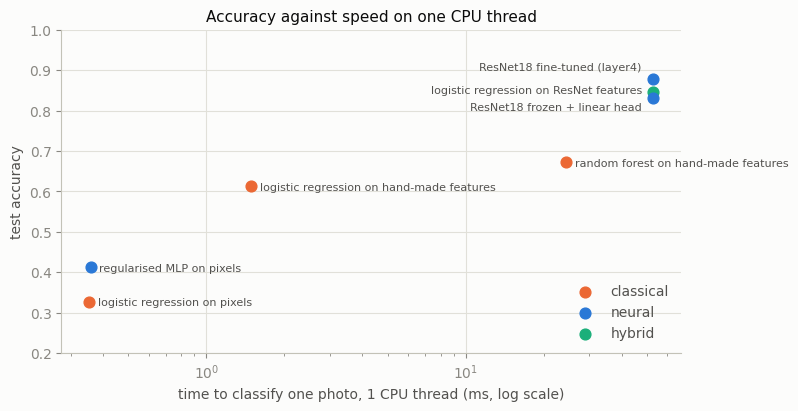

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
left_labels = {"ResNet18 fine-tuned (layer4)": 6, "logistic regression on ResNet features": -1,
               "ResNet18 frozen + linear head": -9}  # the three ResNet points are close: labels on the left
for name, r in speed_table.iterrows():
    ax.scatter(r["ms_1_thread"], r["test_acc"], s=60, color=colors[family[name]], zorder=3,
               label=family[name] if family[name] not in ax.get_legend_handles_labels()[1] else None)
    dx, dy, ha = (-8, left_labels[name], "right") if name in left_labels else (6, -3, "left")
    ax.annotate(name, (r["ms_1_thread"], r["test_acc"]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("time to classify one photo, 1 CPU thread (ms, log scale)")
ax.set_ylabel("test accuracy")
ax.set_ylim(0.2, 1.0)
ax.set_title("Accuracy against speed on one CPU thread")
ax.legend(loc="lower right")
save_figure(fig, "06_accuracy_vs_speed")
plt.show()

**What we see.**

- **Every model is fast enough for a kiosk.** The ResNet18 models take about 53 ms per photo on
  one CPU thread (26 ms with 4 threads). Even on a kiosk CPU 4 times slower, that is about
  0.2 s, much less than the time a visitor needs to look at the screen.
- The classical models and the MLP are even faster (0.3 ms to 24 ms), but much less accurate.
- **Size**: the ResNet18 file weighs 45 MB (11 million parameters stored as 32-bit numbers), the random
  forest 26 MB and the MLP 6.8 MB. All of them fit easily in the memory of a kiosk.
- **Training cost**: the frozen ResNet + linear head trains in 17 s on this laptop CPU (the
  features of the 1 061 training paintings, then 0.4 s for the head). Fine-tuning takes 153 s (about
  2.5 minutes). No GPU is needed.

In [10]:
save_results("06_final", {
    "classical_tuning": tuning,
    "classical_settings": {n: c["setting"] for n, c in classical.items()},
    "reproducibility_check": check.to_dict(orient="records"),
    "test": test_table.reset_index().to_dict(orient="records"),
    "paired": paired.to_dict(orient="records"),
    "best_model_test_per_class": per_class.reset_index(names="style").to_dict(orient="records"),
    "speed": speed_table.reset_index().to_dict(orient="records"),
    "cpu_threads_available": torch.get_num_threads(),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/06_final.json')

## 5. Our recommendation to the director

**Yes, a neural network is worth it, but a pretrained one that we reuse, not one we train from zero.**
We recommend **ResNet18, frozen, with a linear head** for the kiosks.

| Criterion | Best classical model (random forest, hand-made features) | ResNet18 frozen + linear head |
|---|---|---|
| Test accuracy (220 new paintings) | 67.3 % (60.9 to 73.6) | **83.0 %** (78.6 to 88.6) |
| Time per photo, 1 CPU thread | 24 ms | 53 ms |
| Model file | 26 MB | 45 MB |
| Training on a laptop CPU | 1 s | 17 s |
| GPU needed | no | no |

Why:

1. **Accuracy.** It is 16 points better than the best classical model (interval 9 to 24 points). With
   the classical model, about one visitor in three would get a wrong style; with the ResNet, about one
   in six.
2. **The kiosk CPU is enough.** One photo takes about 53 ms on one thread of a laptop CPU. A
   visitor does not notice it.
3. **Cheap for a small team.** Nobody needs to train a big network: the ResNet stays as it was
   downloaded, and only a small linear layer is trained, in seconds, on an ordinary laptop. When the
   collection changes (new paintings, a new style), we compute the new features and train the head
   again. The head can even be a standard logistic regression (84.5 %).

What we do **not** recommend:

- **Our MLP on pixels** (41.4 %): a network built and trained from zero needs far more images.
- **A classical model alone** (61 to 67 %): fast and small, but too often wrong for a museum guide.
- **Fine-tuning, for now.** It costs minutes instead of seconds, and our data cannot say whether it is
  better: it lost on validation and won on test. It is the first thing to try again with more data.

**Limits and next steps before production:**

1. **Real photos.** Visitors' photos have angles, reflections and frames, unlike our clean scans. We
   should test a few hundred real kiosk photos before the launch.
2. **More styles and more paintings.** Our study covers 5 styles and 300 paintings per style.
3. **Unknown painters.** 59 % of the paintings have an unknown painter, so some painter leakage may
   remain (notebook 05 measured +11 points when a painter is seen in training).
4. **The real kiosk.** Measure the speed on the real kiosk hardware. If memory is tight, the model can
   be stored with 8-bit numbers (about 4 times smaller); we did not test it here.